# Happy, sad and surprised faces from a sentence

This notebook extends the happy and sad notebook,

https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/happy-sad-diffusion/happy_sad_diffusion.ipynb

in two steps.

* A **third expression**, surprised, with the mouth wide open. The prompt becomes a **one-hot** of three numbers: $[1, 0, 0]$ asks for a happy face, $[0, 1, 0]$ for a sad one, $[0, 0, 1]$ for a surprised one. The forward process, the denoiser, the training and the generation are those of the first notebook.
* A **sentence as the prompt**. BERT, a transformer trained by Google, turns a sentence into $768$ numbers. One linear layer on top learns from $30$ short descriptions which expression a sentence asks for, and its answer, as a one-hot, becomes the prompt of the denoiser.

**Do the happy and sad exercise first.** This notebook extends it, and its folded cells reuse that notebook's code, answers included:

https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/happy-sad-diffusion/happy_sad_diffusion.ipynb

**Your part: five tasks, each marked with 🎯, one line each.** The network's first layer in part 2, the vector of `[CLS]` in part 5, the classifier and its loss in part 6, and the one-hot of the best score in part 7. Everything else is done for you. The cells that show only a title make the faces, train the denoiser and generate faces as in the happy and sad notebook, and draw the pictures: run them, there is nothing to change inside. Their Show code button opens one if you are curious. Run the cells from top to bottom, then try your own sentences at the end.

**Did it work?** After each task, a cell marked ✅ checks your line and prints PASS or NOT YET, with your numbers and the expected ones. After part 7 a banner says whether the whole thing works: whether the classifier reads the thirty sentences right and the denoiser draws the face they ask for.

**Stuck?** Every task has a hint below it: click it to open it. And this worked example builds a classifier, the season of a sunrise, with the same kinds of lines as tasks 3 and 4, all of its training code shown:

https://colab.research.google.com/github/eth-bmai-hs26/w4-cx-public/blob/main/sunrise-cnn/sunrise_season_classifier.ipynb

In [2]:
#@title Imports { display-mode: "form" }
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(0)   # seeded: the same noise and the same starting weights on every computer

In [3]:
#@title The checks of the ✅ cells { display-mode: "form" }
from IPython.display import HTML, display


def shown(values):
    # Numbers to four decimals, anything else as Python writes it.
    return [round(v, 4) if isinstance(v, float) else v for v in values]


def check(what, yours, expected):
    # PASS when yours is the expected number, or the expected numbers, to four decimals; NOT YET otherwise.
    mine = list(yours) if isinstance(yours, (tuple, list)) else [yours]
    goal = list(expected) if isinstance(expected, (tuple, list)) else [expected]
    same = len(mine) == len(goal) and all(isinstance(m, (int, float)) and abs(m - g) < 0.00005
                                          for m, g in zip(mine, goal))
    if same:
        print(f"PASS     {what}")
    else:
        print(f"NOT YET  {what}")
        print(f"         yours:    {shown(mine)}")
        print(f"         expected: {shown(goal)}")


def check_that(what, holds, otherwise):
    # PASS when it holds, NOT YET with the reason otherwise.
    if holds:
        print(f"PASS     {what}")
    else:
        print(f"NOT YET  {what}")
        print(f"         {otherwise}")


def banner(worked, headline, detail):
    # The verdict in large letters: a blue tick when it worked, a vermillion cross when not.
    colour, mark, ground = ("#0072B2", "&#10003;", "#E6F0F7") if worked else ("#D55E00", "&#10007;", "#FBEAE1")
    display(HTML(
        f'<div style="border-left: 10px solid {colour}; background: {ground}; color: #212121; '
        f'padding: 14px 20px; margin: 4px 0 14px 0; font-family: sans-serif;">'
        f'<div style="font-size: 26px; font-weight: bold; color: {colour};">{mark} {headline}</div>'
        f'<div style="font-size: 16px; margin-top: 8px;">{detail}</div></div>'))

## 1. The faces

The happy and sad faces of the first notebook, and a surprised one. Each face may again sit one pixel higher or lower and one pixel further left or right: $9$ faces per expression, $27$ in all. Each face comes with its one-hot.

In [4]:
#@title The 27 faces and their one-hots { display-mode: "form" }
EYES = [(2, 3), (2, 5)]                                          # (row, column) of every ink pixel
HAPPY = [(5, 2), (6, 3), (6, 4), (6, 5), (5, 6)]                 # the mouth curves up
SAD = [(6, 2), (5, 3), (5, 4), (5, 5), (6, 6)]                   # the mouth curves down
SURPRISED = [(5, 3), (5, 4), (5, 5), (6, 3), (6, 5), (7, 3), (7, 4), (7, 5)]   # the mouth is wide open
EXPRESSIONS = ["happy", "sad", "surprised"]

faces, prompts = [], []
for one_hot, mouth in [([1, 0, 0], HAPPY), ([0, 1, 0], SAD), ([0, 0, 1], SURPRISED)]:
    for dy in [-1, 0, 1]:                                        # one pixel up, none, one pixel down
        for dx in [-1, 0, 1]:                                    # one pixel left, none, one pixel right
            face = torch.zeros(9, 9)
            for row, col in EYES + mouth:
                face[row + dy, col + dx] = 1.0
            faces.append(face.flatten())                         # the 81 pixels in one row
            prompts.append(one_hot)
faces = torch.stack(faces)                                       # 27 faces, 81 numbers each
prompts = torch.tensor(prompts, dtype=torch.float32)             # 27 one-hots, 3 numbers each
print(faces.shape, prompts.shape)

torch.Size([27, 81]) torch.Size([27, 3])


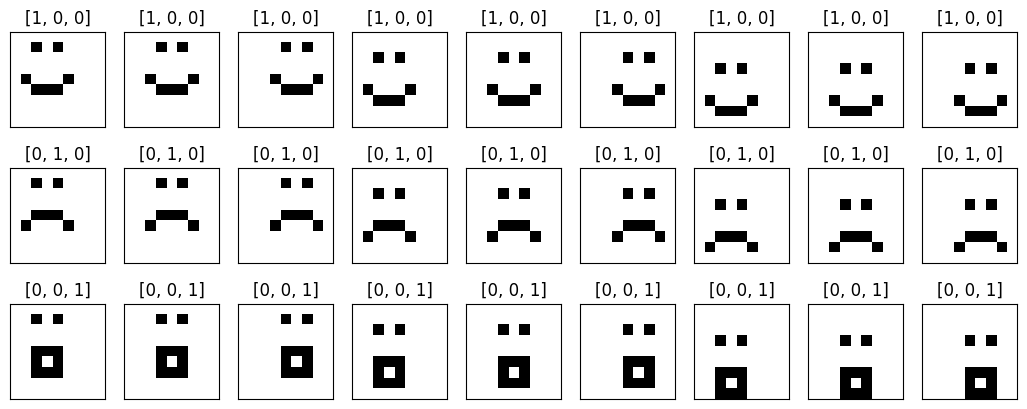

In [5]:
#@title Picture of the 27 faces { display-mode: "form" }
def show(ax, picture, title=""):
    ax.imshow(picture.reshape(9, 9), cmap="Greys", vmin=0, vmax=1)
    ax.set(xticks=[], yticks=[], title=title)


fig, axes = plt.subplots(3, 9, figsize=(13, 5))
for ax, face, one_hot in zip(axes.flat, faces, prompts):
    show(ax, face, str(one_hot.int().tolist()))
plt.show()

## 2. The forward process and the denoiser

As in the first notebook, with one change: the network reads $81 + 1 + 3 = 85$ numbers, the noisy picture, the step $t$ (as $t/T$) and the one-hot.

🎯 **Task 1.** The network's first line is missing: the layer that takes the $81 + 1 + 3 = 85$ numbers it reads, the noisy picture, the step and the one-hot, to $128$ neurons, followed by its `nn.ReLU()`. Write it in the style of the next line, an `nn.Linear(numbers in, numbers out)` followed by an `nn.ReLU()`.

<details>
<summary><b>Hint for task 1</b> (click to open)</summary>

In the happy and sad notebook this line read the noisy picture, the step and the bit: `nn.Linear(81 + 1 + 1, 128), nn.ReLU(),`. Only the last number changes: the one-hot has three numbers where the bit had one.

</details>

In [9]:
T = 20                                                           # the number of steps from a face to pure noise


def add_noise(face, noise, t):
    return (1 - t / T) * face + (t / T) * noise                 # the picture at step t


# ============================================================
# 🎯 TASK 1: the network's first layer
# ============================================================
net = nn.Sequential(
    # 🎯 COMPLETE THIS LINE: the first layer, and its nn.ReLU()
    nn.Linear(81 + 1 + 3, 128), nn.ReLU(),
    nn.Linear(128, 128), nn.ReLU(),
    nn.Linear(128, 81),                                          # out: its guess of the clean face
)


def previous_picture(x, t, prompt):
    guess = net(torch.cat([x, t / T, prompt], dim=1))            # the network's guess of the clean face
    return x + (guess - x) / t                                   # one step from x_t towards it: the estimate of x_{t-1}

In [8]:
#@title ✅ Check task 1 { display-mode: "form" }
first = net[0]
check_that("the network starts with an nn.Linear", isinstance(first, nn.Linear), f"it starts with {first}")
if isinstance(first, nn.Linear):
    check("its first layer reads 85 numbers: the noisy picture, the step and the one-hot", first.in_features, 85)
    check("and passes them to 128 neurons", first.out_features, 128)
check_that("an nn.ReLU() comes right after it", isinstance(net[1], nn.ReLU), f"the second piece is {net[1]}")

PASS     the network starts with an nn.Linear
PASS     its first layer reads 85 numbers: the noisy picture, the step and the one-hot
PASS     and passes them to 128 neurons
NOT YET  an nn.ReLU() comes right after it
         the second piece is Linear(in_features=128, out_features=128, bias=True)


## 3. Training

The same loop and the same threshold as in the first notebook, now over the $27$ faces. It takes a few seconds longer.

In [10]:
#@title Training the denoiser, as in the happy and sad notebook { display-mode: "form" }
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

loss = 1.0                                                       # any start above the threshold
while loss > 0.012:
    pick = torch.randint(0, 27, (256,))                          # 256 faces picked at random
    face, prompt = faces[pick], prompts[pick]
    noise = torch.randn_like(face)                               # a noise picture for each face
    t = torch.randint(1, T + 1, (256, 1)).float()                # a step between 1 and T for each face
    x_t = add_noise(face, noise, t)                              # the noisy picture at step t
    x_previous = add_noise(face, noise, t - 1)                   # the true picture one step earlier
    loss = ((previous_picture(x_t, t, prompt) - x_previous) ** 2).sum(dim=1).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"\rloss: {loss.item():.4f}", end="")

loss: 0.0117

## 4. Generating faces from a one-hot

The three steps of the slides, with a one-hot as the prompt. `torch.eye(3)` holds the three one-hots, one per row.

In [11]:
#@title Generating faces, as in the happy and sad notebook { display-mode: "form" }
def generate(one_hot, how_many=10):
    with torch.no_grad():
        x = torch.randn(how_many, 81)                            # 1) sample noise: x_T
        prompt = one_hot.repeat(how_many, 1)                     # the same one-hot for every face
        t = T
        while t > 0:                                             # 2) for t = T, T-1, ..., 1:
            step = torch.full((how_many, 1), float(t))
            x = previous_picture(x, step, prompt)                #    estimate x_{t-1} from x_t
            t = t - 1
    return x                                                     # 3) output x_0

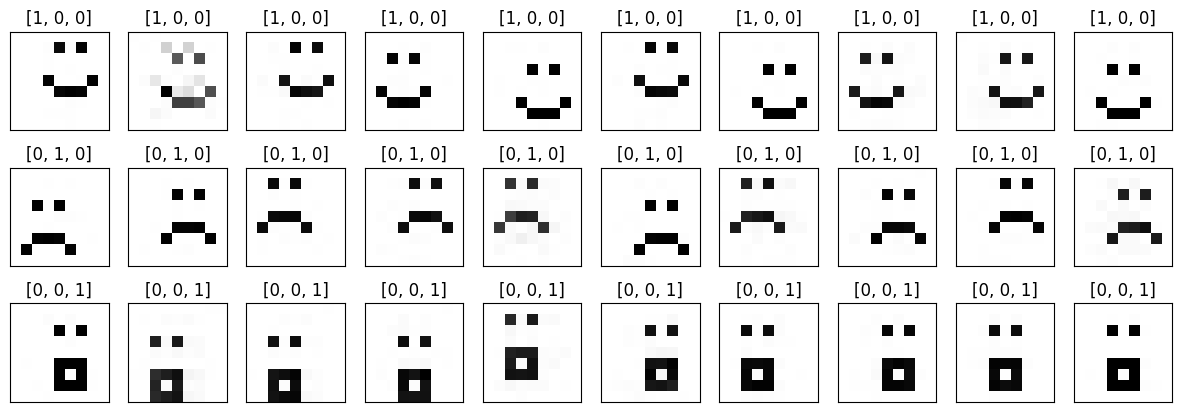

In [12]:
#@title Ten faces for each one-hot { display-mode: "form" }
fig, axes = plt.subplots(3, 10, figsize=(15, 5))
for row, one_hot in zip(axes, torch.eye(3)):                     # the three one-hots, one per row
    for ax, picture in zip(row, generate(one_hot)):
        show(ax, picture, str(one_hot.int().tolist()))
plt.show()

## 5. BERT turns a sentence into 768 numbers

BERT is a transformer, like the ones of weekend 2, trained by Google on English Wikipedia and thousands of books. It cuts a sentence into tokens, words or pieces of words, puts a token of its own, `[CLS]`, in front and another, `[SEP]`, at the end. For every token it computes a vector of $768$ numbers, and the vector of `[CLS]` stands for the whole sentence. BERT is downloaded once, $440$ MB, and used as it is: nothing in it is trained here. Two messages come with the download, and both can be ignored: a warning that no `HF_TOKEN` is set (BERT is public, it needs no token), and a load report that lists seven weights as `UNEXPECTED` (they belong to the two tasks BERT was trained on, guessing hidden words and telling whether one sentence follows another, which this notebook does not need).

🎯 **Task 2.** Complete `embed`. `vectors` holds what BERT computes for the one sentence it was given: a vector of $768$ numbers for every token, `[CLS]` first. Return the vector of `[CLS]`, which stands for the whole sentence.

<details>
<summary><b>Hint for task 2</b> (click to open)</summary>

`vectors` has three dimensions: the sentence (there is only one, number $0$), the token (`[CLS]` is token $0$) and the $768$ numbers. `vectors[0]` is the table of the sentence's tokens, one row per token, and `vectors[0, 0]` is its first row.

</details>

In [14]:
from transformers import AutoTokenizer, AutoModel

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")   # cuts a sentence into tokens and numbers them
bert = AutoModel.from_pretrained("bert-base-uncased")            # BERT itself, 110 million weights


# ============================================================
# 🎯 TASK 2: the vector of [CLS], in embed
# ============================================================
def embed(sentence):
    with torch.no_grad():                                        # BERT is used as it is, never trained here
        ids = tokenizer(sentence, return_tensors="pt").input_ids # the numbers of the tokens, [CLS] first
        vectors = bert(ids).last_hidden_state                    # a vector of 768 numbers for every token
    # 🎯 COMPLETE THIS LINE: the vector of [CLS], for the whole sentence
    return vectors


ids = tokenizer("a flabbergasted woman", return_tensors="pt").input_ids
print(tokenizer.convert_ids_to_tokens(ids[0]))                   # the tokens BERT sees
print(embed("a flabbergasted woman").shape)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['[CLS]', 'a', 'fl', '##ab', '##berg', '##ast', '##ed', 'woman', '[SEP]']
torch.Size([1, 9, 768])


In [15]:
#@title ✅ Check task 2 { display-mode: "form" }
with torch.no_grad():
    ids = tokenizer("a happy face", return_tensors="pt").input_ids
    table = bert(ids).last_hidden_state[0]                       # one row of 768 numbers per token
tokens = tokenizer.convert_ids_to_tokens(ids[0])
yours = embed("a happy face")
check_that("embed gives one vector of 768 numbers", tuple(yours.shape) == (768,),
           f"it gives a tensor of shape {tuple(yours.shape)}")
if tuple(yours.shape) == (768,):
    rows = [k for k, row in enumerate(table) if torch.allclose(row, yours)]
    check_that("it is the vector of [CLS], the first token", rows == [0],
               f"it is the vector of {[tokens[k] for k in rows] or 'no token'}; the tokens are {tokens}")

NOT YET  embed gives one vector of 768 numbers
         it gives a tensor of shape (1, 5, 768)


## 6. Which face does a sentence ask for?

Thirty short descriptions, ten for each expression, made up for this notebook. BERT turns each into its $768$ numbers, and one linear layer learns to give each sentence three scores, one per expression. The loss, cross-entropy, is small when the score of the right expression is well above the other two. It trains in under a second.

🎯 **Task 3.** Write the classifier, one linear layer: the $768$ numbers of a sentence in, one score per expression out.

🎯 **Task 4.** In the loop, write the loss: the cross-entropy of the classifier's scores for the thirty sentences, `classifier(embeddings)`, against their `labels`.

<details>
<summary><b>Hint for task 3</b> (click to open)</summary>

The season classifier of the worked example ends with a layer of the same kind, its head: `head = nn.Linear(16 * 8 * 8, 3)` takes the $1024$ numbers of a picture to $3$ scores, one per season.

</details>

<details>
<summary><b>Hint for task 4</b> (click to open)</summary>

The worked example's loop computes its loss in one call, `nn.functional.cross_entropy(scores, train_seasons[batch])`: the scores first, the true classes second. Here the scores are `classifier(embeddings)` and the true classes `labels`.

</details>

The loop stops after a few hundred steps. If the loss printed under the cell does not fall, stop the cell with the square button next to it and check your lines.

In [ ]:
HAPPY_TEXTS = ["a happy face", "a smiling face", "someone who is glad", "a cheerful person", "she is delighted",
               "he is laughing", "a big smile", "a pleased child", "they look very happy", "a grinning man"]
SAD_TEXTS = ["a sad face", "an unhappy face", "someone who is crying", "a gloomy person", "she is upset",
             "he is miserable", "tears running down a face", "a heartbroken child", "they look very sad",
             "a tearful woman"]
SURPRISED_TEXTS = ["a surprised face", "an astonished face", "someone who is amazed", "a shocked person",
                   "she is stunned", "he is startled", "a mouth wide open in surprise", "a speechless child",
                   "they look very surprised", "an open-mouthed man"]

embeddings, labels = [], []
for label, texts in [(0, HAPPY_TEXTS), (1, SAD_TEXTS), (2, SURPRISED_TEXTS)]:
    for text in texts:
        embeddings.append(embed(text))
        labels.append(label)
embeddings = torch.stack(embeddings)                             # 30 sentences, 768 numbers each
labels = torch.tensor(labels)                                    # 0 happy, 1 sad, 2 surprised
print(embeddings.shape, labels.shape)

In [ ]:
# ============================================================
# 🎯 TASKS 3 AND 4: the classifier, and its loss in the loop below
# ============================================================
# 🎯 COMPLETE THIS LINE: the classifier, one linear layer
classifier = ____
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.001)

loss = 1.0                                                       # any start above the threshold
while loss > 0.01:
    # 🎯 COMPLETE THIS LINE: the cross-entropy of the scores of the 30 sentences against their labels
    loss = ____
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"\rloss: {loss.item():.4f}", end="")

In [ ]:
#@title ✅ Check tasks 3 and 4 { display-mode: "form" }
check_that("the classifier is one nn.Linear", isinstance(classifier, nn.Linear), f"it is {classifier}")
if isinstance(classifier, nn.Linear):
    check("it reads the 768 numbers of a sentence", classifier.in_features, 768)
    check("and gives 3 scores, one per expression", classifier.out_features, 3)
with torch.no_grad():
    chances = classifier(embeddings).softmax(dim=1)              # the three scores as probabilities
right = int((chances.argmax(dim=1) == labels).sum())
sure = chances.gather(1, labels[:, None])[:, 0]                  # the probability of each sentence's own expression
check("after training, the best score is the right expression for all 30 sentences", right, 30)
check_that("and the classifier is sure of it: a probability of at least 0.9 for every sentence",
           bool((sure >= 0.9).all()), f"the lowest is {sure.min().item():.3f}")

## 7. From a sentence to a face

The expression with the best score becomes the one-hot, and the one-hot goes to `generate`.

🎯 **Task 5.** Complete `one_hot_from`. `one_hot` starts as three zeros: put a $1$ at the place of the expression with the best score. `scores.argmax()` is that place, $0$, $1$ or $2$.

<details>
<summary><b>Hint for task 5</b> (click to open)</summary>

`one_hot[k] = 1.0` sets the number at place `k` of `one_hot` to $1$. Here `k` is `scores.argmax()`.

</details>

In [ ]:
# ============================================================
# 🎯 TASK 5: the one-hot of the best score, in one_hot_from
# ============================================================
def one_hot_from(sentence):
    with torch.no_grad():
        scores = classifier(embed(sentence))                     # one score for each expression
    one_hot = torch.zeros(3)
    # 🎯 COMPLETE THIS LINE: a 1 at the place of the best score
    ____
    return one_hot


print(one_hot_from("a joyful face"))

In [ ]:
#@title ✅ Check task 5 { display-mode: "form" }
check("a happy face: a 1 at happy and 0 at the other two", one_hot_from("a happy face").tolist(), [1.0, 0.0, 0.0])
check("a sad face", one_hot_from("a sad face").tolist(), [0.0, 1.0, 0.0])
check("a surprised face", one_hot_from("a surprised face").tolist(), [0.0, 0.0, 1.0])

None of the sentences below is among the thirty: the first three use words for a feeling that the classifier never saw, the last three name no feeling at all.

In [ ]:
#@title Faces for six new sentences { display-mode: "form" }
sentences = ["a blissful baby", "a sorrowful face", "a flabbergasted woman",
             "I just won the lottery", "my dog died yesterday", "I can't believe my eyes"]
fig, axes = plt.subplots(len(sentences), 8, figsize=(12, 10))
for row, sentence in zip(axes, sentences):
    one_hot = one_hot_from(sentence)
    for ax, picture in zip(row, generate(one_hot, how_many=8)):
        show(ax, picture)
    row[0].set_title(f'"{sentence}": {EXPRESSIONS[one_hot.argmax()]}', loc="left")
plt.show()

In [ ]:
#@title Does it draw the face a sentence asks for? { display-mode: "form" }
with torch.no_grad():
    read_right = int((classifier(embeddings).argmax(dim=1) == labels).sum())
drawn_right = 0
for k, sentence in enumerate(["a happy face", "a sad face", "a surprised face"]):
    pictures = generate(one_hot_from(sentence), how_many=10)
    nearest = (pictures[:, None, :] - faces[None, :, :]).abs().mean(dim=2).argmin(dim=1)   # the nearest of the 27 faces
    drawn_right += int((prompts[nearest].argmax(dim=1) == k).sum())
told = (f"The classifier reads {read_right} of the 30 sentences right, and {drawn_right} of the 30 faces drawn for "
        "a happy, a sad and a surprised face have the expression asked for.")
if read_right == 30 and drawn_right >= 27:
    banner(True, "It draws the face a sentence asks for", told)
else:
    banner(False, "Not yet", told + " The checks above show which line is not right yet.")

## 8. Try it

* Write your own sentence in the cell below, a description or a situation, and run it.
* Write a negation, "a face that is not sad". Which face comes out, and why might that be?
* Add sentences of your own to the three lists of part 6, run that cell and the classifier again, and try the sentences that went wrong.

**What BERT brings.** The thirty sentences taught only the last layer which of BERT's directions means which face. Everything else BERT learned from its millions of sentences, which is why it also understands words it never saw here.

**What Stable Diffusion does differently.** It reads its prompt with the text half of CLIP, a transformer like BERT, and gives all of its vectors to the UNet, with no classifier in between, so it can draw what the sentence describes. The classifier here squeezes every sentence into one of three answers, so this model can only ever draw three faces.

In [ ]:
sentence = "a face full of surprise"                             # write your own sentence here
one_hot = one_hot_from(sentence)
print(EXPRESSIONS[one_hot.argmax()], one_hot.tolist())
fig, axes = plt.subplots(1, 10, figsize=(15, 1.9))
for ax, picture in zip(axes, generate(one_hot)):
    show(ax, picture)
plt.show()